# Customer Churn Explorer - step-by-step project notebook

**Business Analytics Workshop | CookieSensei Labs | Python 3.12**

Work through **what we are doing, why it is useful, how the code works, and what its output means**. The explanations are Markdown cells, and the analysis is in editable Python code cells with saved results. All records are fictional teaching data; monetary values are INR.

Keep this notebook with [customer_churn.csv](customer_churn.csv) and [app.py](app.py). The [Markdown companion](EXPLANATION.md) provides a continuous reading version. The source application and data used here match revision `c10a61c36fffdd048b69dd78926e6663bc986fce`.

## Learning route: explain a customer snapshot

By the end, you should be able to trace a business question through selected customers, a pandas calculation, a displayed result, and a suitably limited conclusion. Practice explaining **why the denominator fits the question**, not just how to call a method. You will distinguish customer observations from grouped results, and counts from percentages.

**What one row means:** one fictional customer in a single snapshot. The bundled file has 480 customer records. `customer_id` identifies a customer; `churned` records a status, with 1 meaning churned and 0 retained. Neither the file nor the code supplies an observation window. Consequently, the overall percentage describes this snapshot, rather than a monthly cancellation probability. Monetary amounts are INR; [the original app](app.py) supplies the complete product.

| Tool | Role in this notebook | What you should learn to explain |
| --- | --- | --- |
| Python and `Path` | Express instructions and locate the CSV | Where input comes from and which variables later cells reuse |
| pandas | Hold named columns, select customers, aggregate groups, and export tables | Why the row population and denominator remain visible throughout the analysis |
| Plotly, Matplotlib, and Seaborn | Turn customer or grouped tables into complementary views | Which variables map to axes, colors, groups, and counts |
| Streamlit | Add browser controls and display the same calculations | How changing a selection triggers a new analysis |

Why pandas? The business questions repeatedly ask for operations on named columns: retain selected regions, average a binary flag, compare contract groups, or total selected fees. A `DataFrame` keeps those operations close to the column names and returns inspectable intermediate tables. Business interpretation remains your responsibility.

Use this mental workflow: **define the population; inspect and validate; select rows; calculate; compare; communicate scope and limits**. Before each result, predict its shape: one number, one row per contract, one row per customer, or a contract-by-region matrix. Check your prediction.

## How to work through this notebook

1. Open `TUTORIAL.ipynb` in JupyterLab or VS Code and select the workshop's Python 3.12 environment.
2. Read the question above a code cell, predict the result, then use **Shift+Enter** to run that cell.
3. Run cells from top to bottom. Python variables stay in the kernel's memory; changing an earlier cell requires rerunning the cells that depend on it.
4. Compare the output with the interpretation underneath. Try the checkpoints before moving on.
5. Use **Restart Kernel and Run All Cells** to reproduce the baseline from a clean session. All executable cells here finish without launching a long-running web server.

The first code cell locates this project and configures notebook chart display. It supports starting in the project folder, the workshop folder, or the repository root. It changes only the kernel's working directory; it does not move any files.

The complete Streamlit teaching script later in this notebook is a **reference code block in a Markdown cell**. Copy it into the stated separate `.py` file to launch its browser interface. The runnable `AppTest` section independently inspects the existing `app.py` and demonstrates a filter rerun inside the notebook. These two execution contexts are explained separately.

Saved figure outputs include embedded PNG previews. In a running JupyterLab or VS Code notebook, Plotly can also display interactive figures. A GitHub preview shows the saved notebook and cannot execute Python. Keep the CSV and app beside the notebook when downloading it for execution. Local JupyterLab users can install the notebook interface with `python -m pip install jupyterlab`; the prepared Cloud Lab already supplies it. Analysis package versions are listed in the [workshop setup](../README.md).

In [1]:
from pathlib import Path                  # Represent a folder or filename as a Python object.
import os                                # Change this kernel's working directory when necessary.
import sys                               # Inspect the Python version selected by the kernel.
from IPython.display import display      # Render tables and figures as notebook outputs.
import matplotlib
import plotly.io as pio

# Support opening the notebook from this folder, the workshop, or the repo root.
notebook_start = Path.cwd()
candidate_folders = [
    notebook_start,
    notebook_start / '03_customer_churn',
    notebook_start / 'business_analytics_workshop' / '03_customer_churn',
]
PROJECT_DIR = next(
    (folder for folder in candidate_folders
     if (folder / 'customer_churn.csv').is_file() and (folder / 'app.py').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook with its sibling CSV and app.py in the project folder.')
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)

# Inline figures belong below their code cells; the Plotly renderer is used by JupyterLab/VS Code.
matplotlib.use('module://matplotlib_inline.backend_inline')
pio.renderers.default = 'plotly_mimetype'
print('Project folder:', PROJECT_DIR.name)
print('CSV and app.py found.')
print('Python:', sys.version.split()[0])

Project folder: 03_customer_churn
CSV and app.py found.
Python: 3.12.14


### Python vocabulary you will use repeatedly

| Code pattern | What it means | Why it appears here |
| --- | --- | --- |
| `name = expression` | Calculate a value and give it a name | Later cells can reuse the result |
| `import pandas as pd` | Import a library with a short alias | `pd.read_csv(...)` calls its CSV reader |
| `frame["column"]` | Select one named column as a Series | Apply a calculation to that measure |
| `frame[mask]` | Keep rows whose Boolean condition is `True` | Define the population being analyzed |
| `.method(...)` | Ask an object to perform an operation | `.sum()`, `.mean()` and `.groupby()` answer different questions |
| `# explanation` | A comment Python does not execute | Describe the purpose of the next operation |
| `f"...{value:.2f}..."` | Put a formatted value into a string | Communicate results without changing the underlying value |

Indentation groups statements inside a `for`, `if`, function or `with` block. Brackets, parentheses and column spelling matter. When a cell fails, read the final error message, inspect the named variable or column, and fix the earliest failed step before continuing.

## 1. Start with the business question

A subscription team wants to know **where observed churn is concentrated**. An overall percentage can hide differences between contracts and regions. The team also wants to compare tenure and satisfaction without mistaking a pattern for a proven cause.

One row is one customer in one snapshot. `churned=1` means marked churned; `churned=0` means marked retained. There is no cancellation date or observation window. We can calculate a snapshot proportion, but not a monthly churn rate, customer lifetime value or future churn prediction.

| Source field | Meaning and unit |
| --- | --- |
| `customer_id` | Synthetic customer identifier |
| `region` | Customer region |
| `contract` | Monthly, Annual or Two year |
| `tenure_months` | Recorded tenure in months |
| `monthly_fee` | Listed monthly charge in INR |
| `support_tickets` | Ticket count without a common documented time window |
| `satisfaction_score` | Recorded score on the intended 1-10 scale |
| `churned` | Intended binary flag, 0 or 1 |

Pandas performs the table operations: reading, selecting, grouping and calculating. Streamlit supplies the browser interface. Plotly creates interactive figures, while Matplotlib and Seaborn provide statistical plots. The libraries help express the analysis; they do not decide what counts as churn or prove why a customer left.

## 2. Load the evidence before calculating results

### Step 01 - Import the tools and locate the CSV

**Question:** Which tools will do the analysis, and are we reading the intended file?

In [2]:
from pathlib import Path             # Handle a file path without a machine-specific directory.
import pandas as pd                  # Read and manipulate tables.
import matplotlib.pyplot as plt      # Create figures and axes.
import seaborn as sns                # Draw statistical boxes and a heatmap.
import plotly.express as px           # Build charts from named DataFrame columns.

DATA_FILE = Path("customer_churn.csv")  # Notebook cells run from this project folder.
print("CSV found:", DATA_FILE.is_file())
print("pandas version:", pd.__version__)

CSV found: True
pandas version: 2.2.3


**Interpretation and reasoning**

The aliases `pd`, `plt`, `sns` and `px` are short names, not different libraries. A relative `Path` is appropriate here because the notebook working directory is explicit. The original script instead uses `Path(__file__).resolve().with_name(...)` to find its sibling CSV when launched elsewhere; notebooks generally do not define `__file__`.

### Step 02 - Read the table and inspect five customers

**Question:** What does one observation look like before we summarize it?

In [3]:
frame = pd.read_csv(DATA_FILE)        # Parse CSV text into a labeled table.
print("Rows:", len(frame))            # len(DataFrame) counts records.
print("Columns:", len(frame.columns))
print(frame.head(5).to_string(index=False))  # Display five rows without a pandas index column.

Rows: 480
Columns: 8
customer_id region contract  tenure_months  monthly_fee  support_tickets  satisfaction_score  churned
  CUST-0001   East Two year             13          799                0                   8        0
  CUST-0002  South  Monthly             27          499                1                   7        1
  CUST-0003   West   Annual             49          499                1                   7        0
  CUST-0004  North Two year             12          999                1                   9        0
  CUST-0005  South  Monthly             54          499                1                   7        0


### Notebook skill - inspect a table directly

The printed preview above is useful in scripts and text reports. A notebook can also render the DataFrame itself as a table. `head(5)` returns a small view for inspection; it does not replace the full source table. Compare the row labels on the left with any business identifier column.

In [4]:
# Display the same source as a notebook table; keep frame unchanged.
display(frame.head(5))

,customer_id,region,contract,tenure_months,monthly_fee,support_tickets,satisfaction_score,churned
0,CUST-0001,East,Two year,13,799,0,8,0
1,CUST-0002,South,Monthly,27,499,1,7,1
2,CUST-0003,West,Annual,49,499,1,7,0
3,CUST-0004,North,Two year,12,999,1,9,0
4,CUST-0005,South,Monthly,54,499,1,7,0


**Interpretation and reasoning**

A `DataFrame` is a table with named columns. `head(5)` inspects five records without changing `frame`. The second customer is marked churned; the other four are retained. Repeated contract names are segment labels, while customer IDs identify individual records.

### Step 03 - Check types and the one-customer-per-row assumption

**Question:** Are we counting customers, and did pandas recognize the measures as numbers?

In [5]:
types = frame.dtypes.astype(str).rename("dtype")  # Make dtype objects readable.
print(types.to_string())
print()
print("Rows:", len(frame))
print("Distinct customer IDs:", frame["customer_id"].nunique())
print("Repeated customer IDs:", frame["customer_id"].duplicated().sum())

customer_id           object
region                object
contract              object
tenure_months          int64
monthly_fee            int64
support_tickets        int64
satisfaction_score     int64
churned                int64

Rows: 480
Distinct customer IDs: 480
Repeated customer IDs: 0


**Interpretation and reasoning**

Selecting one column returns a `Series`. Its `nunique()` result confirms that this file has one distinct ID per row. ID uniqueness is an additional teaching check: the original app reports exact duplicate rows but does not enforce unique customer IDs. Appending multiple snapshots would change what counting rows means.

### Step 04 - Validate the input used by the existing app

**Question:** Can the fields be analyzed without silently discarding incomplete rows?

In [6]:
required_columns = [
    "customer_id", "region", "contract", "tenure_months",
    "monthly_fee", "support_tickets", "satisfaction_score", "churned",
]
numeric_columns = [
    "tenure_months", "monthly_fee", "support_tickets",
    "satisfaction_score", "churned",
]

# Reject incomplete schemas instead of calculating from missing fields.
if not set(required_columns).issubset(frame.columns):
    raise ValueError("The CSV is missing required columns.")
if frame.empty:
    raise ValueError("The CSV contains no rows.")

for column in numeric_columns:
    # Reject unparseable text rather than silently replacing it with missing values.
    frame[column] = pd.to_numeric(frame[column], errors="raise")

if frame[required_columns].isna().any().any():
    # First any() reduces each column; the second asks whether any column failed.
    raise ValueError("Fill missing values in the required analysis columns first.")

print("Required-column, nonempty and numeric checks passed.")
print("Missing source cells:", frame.isna().sum().sum())
print("Exact duplicate source rows:", frame.duplicated().sum())

Required-column, nonempty and numeric checks passed.
Missing source cells: 0
Exact duplicate source rows: 0


**Interpretation and reasoning**

These checks match the app's central loading rules. They do not remove duplicates, fill missing values or enforce business ranges. A numeric value of 2 in churned would pass conversion; a later cell demonstrates the consequence. The original app catches specified loading exceptions, displays `st.error(...)`, and uses `st.stop()` to end the current run.

## 3. Select a population and answer its questions

A filter defines the denominator of the analysis. We first reproduce the app's default of selecting every region and contract. Later we create a separate focused subset without silently changing the population behind earlier outputs.

A Boolean mask gives each row `True` or `False`. Selecting `table[mask]` keeps True rows. Applying two filters in sequence means both conditions must hold.

### Checkpoint: predict the population

Before removing one region, predict which customers disappear and which KPI denominators change. Inspect the resulting count. The selection changes the analytical population, not the source file.

### Step 05 - Reproduce the default sidebar selections in Python

**Question:** Which customers will contribute to the cards, charts and report?

In [7]:
selected_regions = sorted(frame["region"].unique())
selected_contracts = sorted(frame["contract"].unique())

filtered = frame.copy()  # Preserve the source table for source-quality reporting.
filtered = filtered[filtered["region"].isin(selected_regions)]
filtered = filtered[filtered["contract"].isin(selected_contracts)]
if filtered.empty:
    raise ValueError("No rows match these selections.")

print("Regions:", ", ".join(selected_regions))
print("Contracts:", ", ".join(selected_contracts))
print(f"Selected customers: {len(filtered)} of {len(frame)}")

Regions: East, North, South, West
Contracts: Annual, Monthly, Two year
Selected customers: 480 of 480


**Interpretation and reasoning**

`isin(...)` tests membership in the chosen list. The app's multiselect widgets supply these lists. Clearing every option selects no rows; it does not mean select all. The app stops an empty selection before attempting rankings or plots.

### Step 06 - Translate the binary flag into readable chart labels

**Question:** How can a chart show meaningful group names instead of 0 and 1?

In [8]:
# map() applies the dictionary to each flag and preserves the original numeric field.
filtered["status"] = filtered["churned"].map({0: "Retained", 1: "Churned"})
print(filtered[["customer_id", "churned", "status"]].head(5).to_string(index=False))

customer_id  churned   status
  CUST-0001        0 Retained
  CUST-0002        1  Churned
  CUST-0003        0 Retained
  CUST-0004        0 Retained
  CUST-0005        0 Retained


**Interpretation and reasoning**

The new status column is for readable display and grouping. The original churned field remains numeric. An unmatched value maps to missing, so binary business validation is different from merely accepting a number.

### Step 07 - Work out five records before trusting an aggregate

**Question:** Why does averaging a binary column answer a percentage question?

In [9]:
sample = filtered.head(5)  # A hand-calculation sample, not a new application filter.
sample_churned = sample["churned"].sum()
sample_count = len(sample)

print("Flags:", sample["churned"].tolist())
print("Churned count:", sample_churned)
print("Snapshot proportion:", sample_churned / sample_count)
print("Mean of flags:", sample["churned"].mean())
print("Average satisfaction:", sample["satisfaction_score"].mean())
print(
    "Listed fee for churned sample customers:",
    sample.loc[sample["churned"] == 1, "monthly_fee"].sum(),
)

Flags: [0, 1, 0, 0, 0]
Churned count: 1
Snapshot proportion: 0.2
Mean of flags: 0.2
Average satisfaction: 7.6
Listed fee for churned sample customers: 499


**Interpretation and reasoning**

The flags sum to 1 across 5 customers, so their mean is 1/5. Every 1 contributes one churned customer and every 0 contributes none. The satisfaction mean uses a different column and unit. `loc[mask, column]` selects churned rows and then their fees; only the selected churned customer's fee contributes.

### Step 08 - Calculate the dashboard KPIs with explicit denominators

**Question:** How much churn is observed across the selected population?

In [10]:
# Each customer contributes one binary flag, so mean(flag) is churned count / customer count.
customer_count = len(filtered)  # Denominator: every selected customer.
churned_count = int(filtered["churned"].sum())  # Numerator: one for each churned customer.
churn_rate = filtered["churned"].mean()  # Binary mean equals numerator / denominator.
average_satisfaction = filtered["satisfaction_score"].mean()  # Scores retain their 1-10 unit.
churned_fees = filtered.loc[filtered["churned"] == 1, "monthly_fee"].sum()  # Add fees only for flagged customers.

print(f"Customers: {customer_count:,}")
print(f"Churned customers: {churned_count:,}")
print(f"Snapshot churn: {churned_count}/{customer_count} = {churn_rate:.3%}")
print(f"Card percentage: {churn_rate:.1%}")
print(f"Average satisfaction: {average_satisfaction:.4f} / 10")
print(f"Card satisfaction: {average_satisfaction:.1f} / 10")
print(f"Churned monthly fees: INR {churned_fees:,.0f}")

Customers: 480
Churned customers: 99
Snapshot churn: 99/480 = 20.625%
Card percentage: 20.6%
Average satisfaction: 6.8625 / 10
Card satisfaction: 6.9 / 10
Churned monthly fees: INR 84,101


**Interpretation and reasoning**

The `.1%` formatter converts a proportion to percentage text; do not multiply by 100 first. Display rounding leaves the stored rate unchanged. INR 84,101 adds listed monthly fees belonging to marked-churned records. Without cancellation dates or billing history, it is not measured revenue lost in a particular month.

### Checkpoint: distinguish counts from rates

Predict the grouped table's row meaning. Must the contract with the most churned customers have the highest percentage? Name each group's numerator and denominator, then check your reasoning.

### Step 09 - Compare contracts with rates and customer counts

**Question:** Does the overall percentage hide contract differences?

In [11]:
contract_summary = filtered.groupby("contract").agg(
    customers=("churned", "size"),  # Denominator: all records in the contract group.
    churned=("churned", "sum"),     # Numerator: sum of binary flags.
    churn_rate=("churned", "mean"), # Numerator divided by denominator.
)
contract_summary["churn_pct"] = contract_summary["churn_rate"] * 100

print(contract_summary[["customers", "churned", "churn_pct"]].round(4).to_string())
print()
highest_contract = contract_summary["churn_rate"].idxmax()  # Return a label, not the value.
print("Highest observed contract proportion:", highest_contract)

          customers  churned  churn_pct
contract                               
Annual          167       29    17.3653
Monthly         159       53    33.3333
Two year        154       17    11.0390

Highest observed contract proportion: Monthly


**Interpretation and reasoning**

`groupby` separates customers, then named aggregation specifies each calculation. The original app displays customer counts and rates; the extra churned-count column here makes the numerator auditable. Monthly leads this snapshot, but these groups differ in characteristics as well as contract type, so no causal conclusion follows.

### Step 10 - Show why group percentages must be weighted

**Question:** Can we average three contract percentages to obtain overall churn?

In [12]:
overall_from_counts = contract_summary["churned"].sum() / contract_summary["customers"].sum()

# This different statistic gives each contract equal weight, regardless of group size.
unweighted_contract_mean = contract_summary["churn_rate"].mean()

print(f"Customer-weighted overall rate: {overall_from_counts:.4%}")
print(f"Unweighted mean of contract rates: {unweighted_contract_mean:.4%}")
print(f"Direct mean of customer flags: {filtered['churned'].mean():.4%}")

Customer-weighted overall rate: 20.6250%
Unweighted mean of contract rates: 20.5792%
Direct mean of customer flags: 20.6250%


**Interpretation and reasoning**

The first and third results agree because both give each customer equal weight. The middle statistic gives each contract equal weight. Their values happen to be close because group sizes are similar; the methods remain different. Overall churn uses summed numerators divided by summed denominators.

### Step 11 - Compare retained and churned customer profiles

**Question:** How do tenure and satisfaction differ between observed statuses?

In [13]:
# Summarize each observed status separately; median describes the middle customer value.
status_summary = filtered.groupby("status").agg(
    customers=("churned", "size"),
    median_satisfaction=("satisfaction_score", "median"),
    median_tenure=("tenure_months", "median"),
)
print(status_summary.to_string())

          customers  median_satisfaction  median_tenure
status                                                 
Churned          99                  6.0           31.0
Retained        381                  7.0           32.0


**Interpretation and reasoning**

A median is the middle ordered value, not a sum divided by count. It is useful with distributions when extremes affect a mean. Group sizes differ substantially. Satisfaction timing is unknown, so this comparison does not establish whether dissatisfaction preceded or followed churn.

### Step 12 - Count customers in contract-region segments

**Question:** How much evidence lies behind each detailed percentage?

In [14]:
# Count the denominator for each observed contract-and-region combination.
segment_counts = filtered.groupby(["contract", "region"]).size()
print(segment_counts.rename("customers").reset_index().to_string(index=False))
print()
print("Observed segment cells:", len(segment_counts))
print("Smallest observed cell:", int(segment_counts.min()))
print("Cells with fewer than 20 customers:", int((segment_counts < 20).sum()))

contract region  customers
  Annual   East         31
  Annual  North         43
  Annual  South         49
  Annual   West         44
 Monthly   East         42
 Monthly  North         23
 Monthly  South         49
 Monthly   West         45
Two year   East         36
Two year  North         40
Two year  South         34
Two year   West         44

Observed segment cells: 12
Smallest observed cell: 23
Cells with fewer than 20 customers: 0


**Interpretation and reasoning**

Grouping on two names creates combined segments. The app's threshold of 20 is an illustrative caution, not a statistical guarantee. The complete count table is displayed after the report Markdown in the original Full report tab. Its Markdown download contains the summary sentence but not that separate table.

### Step 13 - Build the percentage matrix for the heatmap

**Question:** Which combined groups are hidden by a contract-wide average?

In [15]:
segments = filtered.pivot_table(
    index="contract",     # Matrix rows.
    columns="region",     # Matrix columns.
    values="churned",     # Binary measure to summarize.
    aggfunc="mean",       # Churned customers divided by all customers in the cell.
) * 100                  # Numeric percentages for chart annotations.

print(segments.round(2).to_string())

region     East  North  South   West
contract                            
Annual    22.58  16.28  12.24  20.45
Monthly   40.48  43.48  32.65  22.22
Two year   5.56   7.50  17.65  13.64


**Interpretation and reasoning**

Monthly/North comes from ten churned customers out of 23, not from 43.48% of all churned customers. An unobserved combination would have a missing result, not a measured zero-percent result.

## 4. Produce the five chart types

Each chart cell calls `display(fig)` to render its output; Matplotlib cells then close the figure handle while keeping that output visible. The image is the real figure generated from the preceding calculations. In the original app, `st.plotly_chart` or `st.pyplot` sends the figure to the browser; Matplotlib figures are then closed to avoid accumulating resources across reruns.

The saved PNGs are static. Plotly hover and zoom are available when the figure is displayed in a supporting notebook or the Streamlit application.

### Checkpoint: audit a percentage before coloring it

Choose a contract-region cell and find its denominator. What information disappears if you keep only its heatmap color? Explain why the contract bar and heatmap answer different questions.

### Step 14 - Plot contract churn with denominators on hover

**Question:** Which contract has the highest observed proportion?

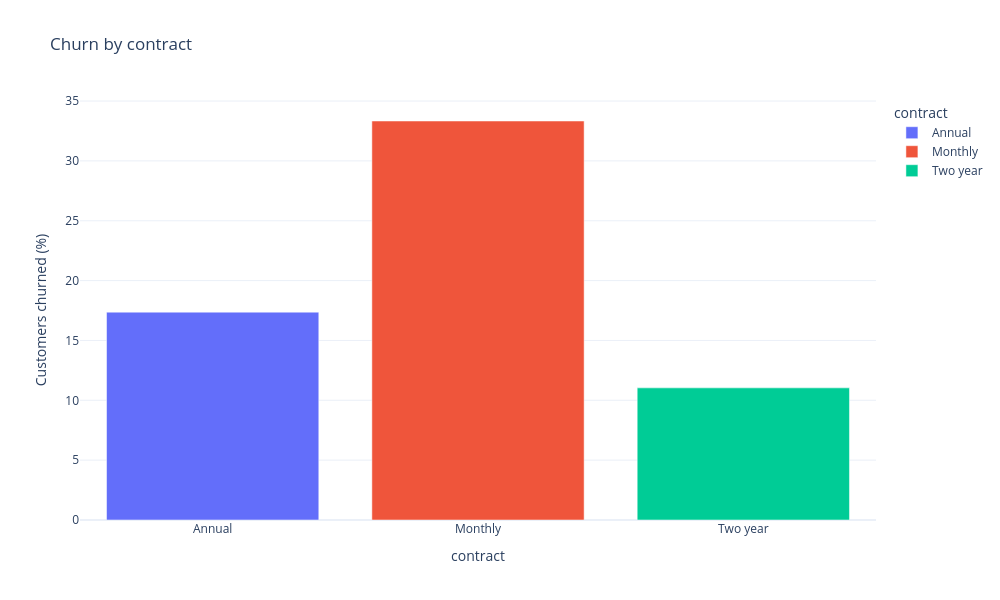

In [16]:
contracts = contract_summary.reset_index()  # Keep contract as a named plotting column.
fig = px.bar(
    contracts, x="contract", y="churn_pct", color="contract",
    hover_data=["customers"], title="Churn by contract",
    labels={"churn_pct": "Customers churned (%)"},
)
fig.update_layout(template="plotly_white")  # Presentation only.
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Bar height is a percentage, not total customers or fees. The live figure supplies customer counts on hover, and the earlier table prints them. This identifies a segment for investigation, not the effect of moving someone to another contract.

### Step 15 - Plot customers in tenure and fee space

**Question:** Do the statuses occupy different parts of tenure and fee space?

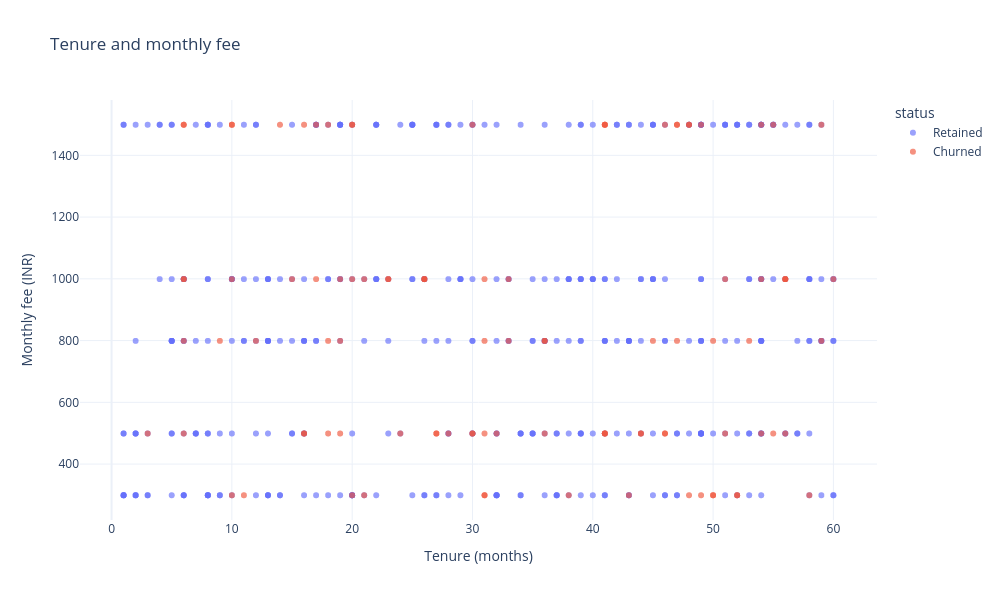

In [17]:
fig = px.scatter(
    filtered,  # Individual customer rows, not aggregated contracts.
    x="tenure_months", y="monthly_fee", color="status",
    hover_data=["customer_id", "contract", "satisfaction_score"],
    opacity=0.65,  # Help reveal overlap.
    title="Tenure and monthly fee",
    labels={"tenure_months": "Tenure (months)", "monthly_fee": "Monthly fee (INR)"},
)
fig.update_layout(template="plotly_white")
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Each point is one customer. Multiple customers can share coordinates, so visual density is approximate. This code places observations and labels their known status; it fits no regression, classifier or probability model.

### Step 16 - Compare tenure distributions using shared bins

**Question:** Are recorded tenures concentrated early or late in each status?

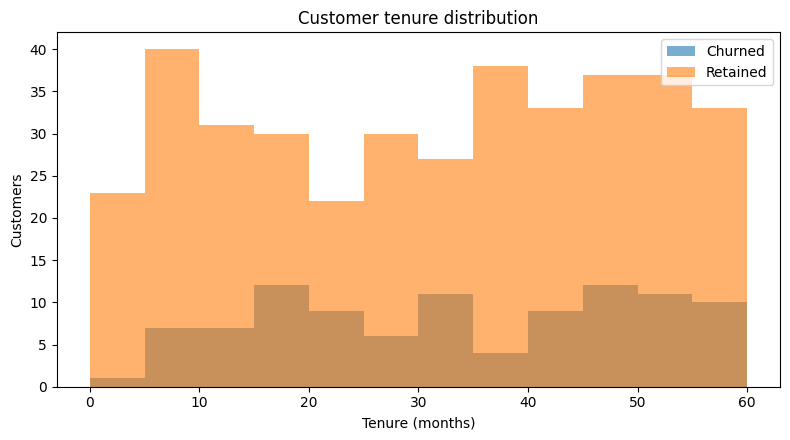

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for status, group in filtered.groupby("status"):
    # Common boundaries give both groups the same five-month intervals.
    ax.hist(group["tenure_months"], bins=12, range=(0, 60), alpha=0.6, label=status)
ax.set(
    title="Customer tenure distribution",
    xlabel="Tenure (months)", ylabel="Customers",
)
ax.legend()
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The y-axis counts people, not the probability of churn at a tenure. Retained customers number 381 versus 99 churned, so taller bars can simply reflect the larger group. A tenure-specific churn proportion requires churned count divided by all customers in each band. Values outside the fixed 0-60 range would be omitted from this histogram.

### Step 17 - Compare satisfaction distributions

**Question:** How do the center and spread of satisfaction differ?

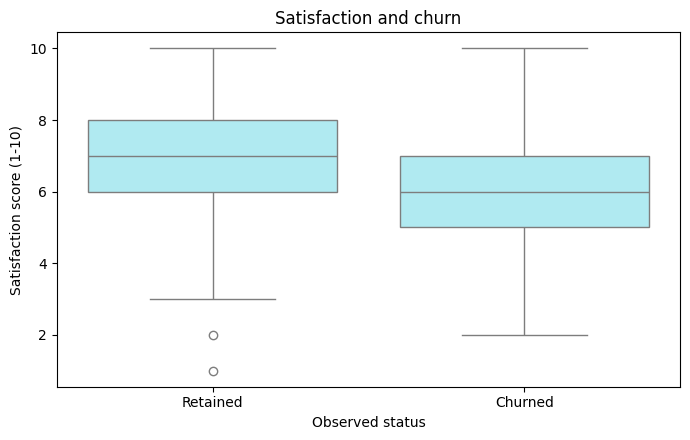

In [19]:
# Each status box summarizes individual scores with a median and quartiles.
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(
    data=filtered, x="status", y="satisfaction_score",
    ax=ax, color="#a5f3fc",
)
ax.set(
    title="Satisfaction and churn",
    xlabel="Observed status", ylabel="Satisfaction score (1-10)",
)
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The center line is the median and the box spans the middle 50%. Default whiskers extend to observations within 1.5 interquartile ranges of the box limits. Separate points are potential outliers, not automatically errors. Recorded differences cannot establish the sequence of dissatisfaction and churn.

### Step 18 - Draw a fixed-scale contract-region heatmap

**Question:** Which combined segments deserve closer examination?

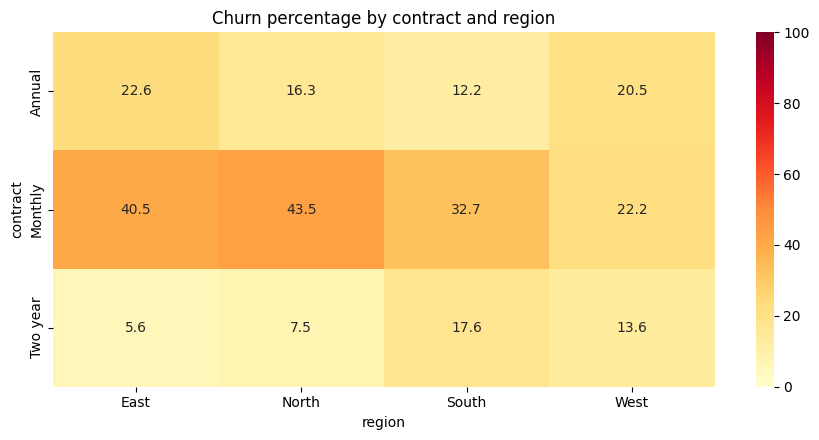

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(
    segments,
    annot=True, fmt=".1f",  # Print one-decimal values in cells.
    cmap="YlOrRd", vmin=0, vmax=100,  # Stable percentage scale.
    ax=ax,
)
ax.set_title("Churn percentage by contract and region")
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

Read each cell with its sample size. Monthly/North has 23 customers and Monthly/East has 42; similar percentages do not imply equally precise estimates. The fixed scale makes color meaning comparable after filtering. No confidence interval or significance test is calculated.

## 5. Investigate, explain and export

These cells verify a focused question, inspect the numerical evidence and turn measured values into text. They keep the distinction between the complete source and a selected population visible.

### Step 19 - Recalculate a focused selection without changing the baseline

**Question:** Can we reproduce the Monthly/North heatmap result from rows?

In [21]:
# Equivalent to selecting only North and Monthly in the sidebar.
focus = frame[
    frame["region"].isin(["North"])
    & frame["contract"].isin(["Monthly"])
].copy()

print("Selection: North; Monthly")
print("Customers:", len(focus))
print("Churned:", int(focus["churned"].sum()))
print(f"Snapshot churn: {focus['churned'].mean():.4%}")
print(f"Listed fees of churned customers: INR {focus.loc[focus['churned'] == 1, 'monthly_fee'].sum():,.0f}")
print("Original tutorial selection still contains:", len(filtered), "customers")

Selection: North; Monthly
Customers: 23
Churned: 10
Snapshot churn: 43.4783%
Listed fees of churned customers: INR 8,890
Original tutorial selection still contains: 480 customers


**Interpretation and reasoning**

The & operator combines Boolean `Series` element by element. A separate `focus` table leaves the baseline `filtered` table unchanged. Monthly is the contract name; it does not turn the snapshot result into a monthly churn rate.

### Step 20 - Inspect numeric summaries with units in mind

**Question:** What are the ranges, centers and spreads of the measures?

In [22]:
# Select numeric measures only; describe() supplies counts, averages, spread and quartiles.
numeric_summary = filtered.select_dtypes(include="number").describe().round(2)
print(numeric_summary.to_string())

       tenure_months  monthly_fee  support_tickets  satisfaction_score  churned
count         480.00       480.00           480.00              480.00   480.00
mean           31.30       845.88             1.64                6.86     0.21
std            17.48       426.41             1.56                1.69     0.41
min             1.00       299.00             0.00                1.00     0.00
25%            16.00       499.00             0.00                6.00     0.00
50%            32.00       799.00             1.00                7.00     0.00
75%            47.00       999.00             3.00                8.00     0.00
max            60.00      1499.00             5.00               10.00     1.00


**Interpretation and reasoning**

`describe()` reports available count, mean, sample standard deviation, extrema and quartiles; 50% is the median. The churn mean is a proportion while the support-ticket mean is a count average. The text status column is excluded. Identical operations can have different business meanings.

### Checkpoint: trace the scope of a sentence

The focused North/Monthly example used a separate object. Has baseline `filtered` changed? Identify the population behind each report variable; correct arithmetic can still describe the wrong selection.

### Step 21 - Build scope and answer sentences from measured variables

**Question:** How does the app explain results without inventing a narrative?

In [23]:
scope_parts = []
for column in frame.select_dtypes(include="object").columns:
    if frame[column].nunique() <= 12:  # Keep the scope description compact.
        values = ", ".join(map(str, sorted(filtered[column].unique())))
        scope_parts.append(column.replace("_", " ") + ": " + values)
scope = "; ".join(scope_parts)

insights = [
    (
        "How much churn is observed?",
        f"{churned_count} of {customer_count} customers are marked churned ({churn_rate:.2%}).",
    ),
    (
        "Which contract has the highest observed proportion?",
        f"{highest_contract}: {contract_summary.loc[highest_contract, 'churn_rate']:.1%} "
        f"among {contract_summary.loc[highest_contract, 'customers']} customers.",
    ),
]
print("Scope:", scope)
for question, answer in insights:
    print(question)
    print(answer)

Scope: region: East, North, South, West; contract: Annual, Monthly, Two year
How much churn is observed?
99 of 480 customers are marked churned (20.62%).
Which contract has the highest observed proportion?
Monthly: 33.3% among 159 customers.


**Interpretation and reasoning**

The sentences are deterministic f-strings inserting calculated values. `loc` retrieves the same group's rate and denominator. There is no language-model call. The original generic datetime-scope loop processes nothing here because the source has no date column.

### Step 22 - Assemble a compact Markdown report

**Question:** How do calculations become a shareable Markdown document?

In [24]:
# Teaching reconstruction of the source's string-building approach.
# The original app creates a longer, twelve-section report.
kpi_values = [
    ("Customers", f"{customer_count:,}"),
    ("Snapshot churn", f"{churn_rate:.2%}"),
    ("Average satisfaction", f"{average_satisfaction:.2f} / 10"),
]
report_parts = [
    "# Customer churn - tutorial report",
    "## Scope\n" + scope,
    "## Results\n| Measure | Value |\n| --- | --- |\n"
    + "\n".join(f"| {name} | {value} |" for name, value in kpi_values),
    "## Questions\n"
    + "\n\n".join(f"### {question}\n{answer}" for question, answer in insights),
    "## Limit\nThis fictional snapshot is not a time-based rate or causal result.",
]
teaching_report = "\n\n".join(report_parts)
print(teaching_report)

# Customer churn - tutorial report

## Scope
region: East, North, South, West; contract: Annual, Monthly, Two year

## Results
| Measure | Value |
| --- | --- |
| Customers | 480 |
| Snapshot churn | 20.62% |
| Average satisfaction | 6.86 / 10 |

## Questions
### How much churn is observed?
99 of 480 customers are marked churned (20.62%).

### Which contract has the highest observed proportion?
Monthly: 33.3% among 159 customers.

## Limit
This fictional snapshot is not a time-based rate or causal result.


**Interpretation and reasoning**

A list keeps sections in order and `join` inserts separators. One resulting string can be rendered and downloaded without recomputing a second analysis. In the original report, the field dictionary is appended to `report_parts[5]`, the KPI section because the title occupies index 0. The source also includes methods, five visual explanations, quality checks and limitations.

### Step 23 - Preview the filtered CSV export

**Question:** What does Download filtered CSV provide?

In [25]:
csv_text = filtered.to_csv(index=False)  # Do not add the internal pandas row index.
print("\n".join(csv_text.splitlines()[:4]))
print()
print("Exported data rows:", len(csv_text.splitlines()) - 1)
print("Contains derived status column:", "status" in filtered.columns)

customer_id,region,contract,tenure_months,monthly_fee,support_tickets,satisfaction_score,churned,status
CUST-0001,East,Two year,13,799,0,8,0,Retained
CUST-0002,South,Monthly,27,499,1,7,1,Churned
CUST-0003,West,Annual,49,499,1,7,0,Retained

Exported data rows: 480
Contains derived status column: True


**Interpretation and reasoning**

The string contains selected source fields plus the derived status column. This cell previews a string and does not overwrite the CSV. The original app supplies it to `st.download_button` under the filename filtered_customer_churn.csv.

### Step 24 - Add business-domain checks as an explicit extension

**Question:** Does numeric parsing prove that values make business sense?

In [26]:
# These are useful additional checks; the original loader does not enforce all of them.
domain_checks = pd.Series({
    "Customer IDs are unique": not frame["customer_id"].duplicated().any(),
    "Churn flags are exactly 0 or 1": frame["churned"].isin([0, 1]).all(),
    "Satisfaction lies in 1-10": frame["satisfaction_score"].between(1, 10).all(),
    "Tenure is nonnegative": frame["tenure_months"].ge(0).all(),
    "Monthly fees are nonnegative": frame["monthly_fee"].ge(0).all(),
    "Support tickets are nonnegative": frame["support_tickets"].ge(0).all(),
})
print(domain_checks.to_string())

Customer IDs are unique            True
Churn flags are exactly 0 or 1     True
Satisfaction lies in 1-10          True
Tenure is nonnegative              True
Monthly fees are nonnegative       True
Support tickets are nonnegative    True


**Interpretation and reasoning**

These checks pass for this file. They are additional validation, not features already enforced by the original app. Integer constraints, finite values, consistent observation windows and accuracy still need consideration for other data.

### Step 25 - Demonstrate an invalid flag on a practice copy

**Question:** What goes wrong when a numeric churn value is not binary?

In [27]:
# Intentionally modify only a tiny copy; frame and the source CSV remain unchanged.
bad_example = frame.head(2).copy()
bad_example.loc[bad_example.index[1], "churned"] = 2
bad_example["status"] = bad_example["churned"].map({0: "Retained", 1: "Churned"})

print(bad_example[["customer_id", "churned", "status"]].to_string(index=False))
print("Raw mean of invalid flags:", bad_example["churned"].mean())
print("Binary-domain check passes:", bad_example["churned"].isin([0, 1]).all())
print("Original source binary-domain check:", frame["churned"].isin([0, 1]).all())

customer_id  churned   status
  CUST-0001        0 Retained
  CUST-0002        2      NaN
Raw mean of invalid flags: 1.0
Binary-domain check passes: False
Original source binary-domain check: True


**Interpretation and reasoning**

The number 2 is parseable, but it contributes two to the churn sum and maps to missing status. Status grouping can exclude that row while raw arithmetic includes it. The controlled corruption explains the validation need without changing the source file or earlier correct analysis.

## 6. Assemble a complete Streamlit teaching app

The Streamlit reference script below runs separately from this notebook and starts a separate application with its own variables. Copy only its Python code into `practice_churn_app.py` beside `customer_churn.csv` and run:

```bash
streamlit run practice_churn_app.py
```

If the workshop dashboard already occupies port 8501, use `streamlit run practice_churn_app.py --server.port 8502` and open the forwarded port.

This compact reconstruction includes the four cards, both interactive figures, three statistical plots, selected records and a short report. The original `app.py` adds full case-study text, field definitions, chart guidance and its twelve-section report.


### Step 26 - Turn the analysis into a browser application

## From notebook reasoning to the customer app

Its Regions and Contracts multiselects produce `selected_region` and `selected_contract`; successive `.isin(...)` masks create `filtered`. An empty selection stops the current script with `st.stop()` before summaries or charts are built; the server remains available for another selection.

| Analysis object or operation | Original app destination | Why this connection matters |
| --- | --- | --- |
| `len(filtered)` and mean of `churned` | Customers and Snapshot churn rate cards | Both refer to the same selected customer population |
| Mean satisfaction and selected churned fees | The other two KPI cards | A score average and a fee sum have different units and meanings |
| `contract_summary` and `contracts` | Contract comparison, leader sentence, and Plotly bar | The group count lets a reader audit each percentage |
| Customer-level `filtered` with `status` | Tenure/fee scatter | Each point remains one customer, rather than an aggregated contract |
| Grouped tenure and satisfaction | Shared-bin histogram and satisfaction boxplot | Counts, median, and spread reveal information hidden by a single average |
| `segments` and `segment_counts` | Heatmap and report-tab sample-size table | A percentage needs its subgroup denominator |
| `insights`, `scope`, and `full_report` | Findings, report display, and Markdown download | Text is assembled from the current selection |

Notebook variables persist between cells. Editing a selection does not refresh KPIs, figures, or reports; rerun dependent cells, or restart and run all. A Streamlit widget change reruns the script from the beginning. This app rereads its CSV without caching, so file edits are picked up on a subsequent rerun. Table sorting, Plotly hover, and switching visible tabs do not apply new analytical filters. All tabs compute during a Streamlit 1.50 run.

The complete Streamlit script is a Markdown reference to save separately and launch with `streamlit run`; it has a shorter report than the original. Executable `AppTest` cells run the sibling `app.py`, inspect metrics, and change widgets. Notebook variables are not injected into that separate execution. In the original, the full segment-count table is displayed after the report text; it is not included as a table in the Markdown download. Always inspect the artifact you intend to share.

### Complete Streamlit teaching script - reference

The following complete script is shown in a **Markdown reference cell**. It is intended for the separate `.py` file described above, because Streamlit renders controls and pages through its own server execution. The analysis cells in this notebook have already calculated and explained the measures used here.

```python
from pathlib import Path
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st

st.set_page_config(page_title="Customer churn - tutorial", layout="wide")
st.title("Customer churn - tutorial")
st.caption("Fictional customer snapshot; monetary amounts are INR.")

# In a saved Python app, __file__ identifies this script's location.
data_file = Path(__file__).resolve().with_name("customer_churn.csv")
required = [
    "customer_id", "region", "contract", "tenure_months",
    "monthly_fee", "support_tickets", "satisfaction_score", "churned",
]
numeric = ["tenure_months", "monthly_fee", "support_tickets", "satisfaction_score", "churned"]
try:
    frame = pd.read_csv(data_file)
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError("Supply a nonempty CSV with the required columns.")
    for column in numeric:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if frame[required].isna().any().any():
        raise ValueError("Fill missing required values.")
except (OSError, ValueError, KeyError) as error:
    st.error(str(error))
    st.stop()  # Stop this run; the server remains available for correction.

# Widgets display controls and return their current Python values.
regions = st.sidebar.multiselect(
    "Regions", sorted(frame["region"].unique()),
    default=sorted(frame["region"].unique()), key="churn_demo_regions",
)
selected_contracts = st.sidebar.multiselect(
    "Contracts", sorted(frame["contract"].unique()),
    default=sorted(frame["contract"].unique()), key="churn_demo_contracts",
)
filtered = frame[
    frame["region"].isin(regions) & frame["contract"].isin(selected_contracts)
].copy()
if filtered.empty:
    st.info("Select at least one region and contract with matching customers.")
    st.stop()

filtered["status"] = filtered["churned"].map({0: "Retained", 1: "Churned"})
churn_rate = filtered["churned"].mean()
fee_total = filtered.loc[filtered["churned"] == 1, "monthly_fee"].sum()

cards = st.columns(4)
cards[0].metric("Customers", f"{len(filtered):,}")
cards[1].metric("Snapshot churn rate", f"{churn_rate:.1%}")
cards[2].metric("Average satisfaction", f"{filtered['satisfaction_score'].mean():.1f} / 10")
cards[3].metric("Churned monthly fees (INR)", f"{fee_total:,.0f}")

dashboard, explore, data_tab, report_tab = st.tabs(["Dashboard", "Explore", "Data", "Report"])
with dashboard:
    contracts = filtered.groupby("contract", as_index=False).agg(
        customers=("churned", "size"), churn_rate=("churned", "mean"),
    )
    contracts["churn_pct"] = contracts["churn_rate"] * 100
    st.plotly_chart(
        px.bar(contracts, x="contract", y="churn_pct", color="contract",
               hover_data=["customers"], title="Churn by contract"),
        use_container_width=True,
    )
    st.plotly_chart(
        px.scatter(filtered, x="tenure_months", y="monthly_fee", color="status",
                   hover_data=["customer_id", "contract"], opacity=0.65,
                   title="Tenure and monthly fee"),
        use_container_width=True,
    )

with explore:
    fig, ax = plt.subplots(figsize=(7, 4))
    for status, group in filtered.groupby("status"):
        ax.hist(group["tenure_months"], bins=12, range=(0, 60), alpha=0.6, label=status)
    ax.set(xlabel="Tenure (months)", ylabel="Customers")
    ax.legend()
    st.pyplot(fig)
    plt.close(fig)  # Release the Matplotlib figure after sending it to the app.

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=filtered, x="status", y="satisfaction_score", ax=ax)
    st.pyplot(fig)
    plt.close(fig)

    segments = filtered.pivot_table(
        index="contract", columns="region", values="churned", aggfunc="mean",
    ) * 100
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.heatmap(segments, annot=True, fmt=".1f", vmin=0, vmax=100, cmap="YlOrRd", ax=ax)
    st.pyplot(fig)
    plt.close(fig)

with data_tab:
    st.dataframe(filtered, hide_index=True, width="stretch")
    st.download_button(
        "Download selected CSV", filtered.to_csv(index=False),
        "tutorial_churn_selection.csv", "text/csv",
    )

# Reuse one calculated report string for browser display and download.
report = (
    "# Customer churn summary\n\n"
    f"Selected customers: {len(filtered)}\n\n"
    f"Snapshot churn: {churn_rate:.2%}\n\n"
    "This fictional snapshot does not establish a monthly rate or causal effect."
)
with report_tab:
    st.markdown(report)
    st.download_button("Download short report", report, "tutorial_churn_report.md", "text/markdown")
```

## Inspect the actual Streamlit application from this notebook

The companion script above is a compact teaching reconstruction. The next executable cells inspect the **existing sibling `app.py`**, which also contains the complete business context, chart explanations and full report.

`AppTest` is Streamlit's testing interface. It runs the application and lets Python inspect the UI elements it produced. It does not start a browser server. We use it here to connect the notebook's calculations with the application's real labels and values. The displayed tables summarize application elements; they are not browser screenshots.

### Load and run the sibling app

`AppTest.from_file(...)` reads a saved Streamlit script; `.run()` executes it with default widget values. The checks stop this cell if the app raises an exception or displays a loading error. Keeping `app.py` beside its CSV lets its `Path(__file__)` lookup work independently of notebook variables.

In [28]:
from streamlit.testing.v1 import AppTest  # Inspect Streamlit output without launching a server.
import logging

# AppTest intentionally runs without a browser session; quiet its context-only warning.
# Application errors are still checked explicitly below.
logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context').setLevel(logging.ERROR)

app_file = PROJECT_DIR / 'app.py'
app_preview = AppTest.from_file(str(app_file), default_timeout=45).run()
if len(app_preview.exception):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.exception))
if len(app_preview.error):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.error))

print('Script:', app_file.name)
print('Title:', app_preview.title[0].value)
print('Default application run completed.')

Script: app.py
Title: Customer Churn Explorer
Default application run completed.


### Read the controls, KPI cards and output containers

The values below come from the application instance that just ran. A metric element has a `label` and a formatted `value`; a multiselect has the current list of choices. The table dimensions describe what the app actually rendered. Chart counts distinguish interactive Plotly figures from Matplotlib/Seaborn images.

In [29]:
# Turn rendered KPI cards into an ordinary table we can inspect in the notebook.
baseline_cards = {metric.label: metric.value for metric in app_preview.metric}
display(pd.DataFrame(baseline_cards.items(), columns=['Dashboard measure', 'Displayed value']))

for widget in app_preview.multiselect:
    print(widget.label + ': ' + ', '.join(map(str, widget.value)))
for widget in app_preview.date_input:
    print(widget.label + ': ' + ' to '.join(map(str, widget.value)))
for widget in app_preview.slider:
    print(widget.label + ': ' + str(widget.value))
for index, table in enumerate(app_preview.dataframe, start=1):
    print(f'Table {index}: {len(table.value)} rows x {len(table.value.columns)} columns')
print('Interactive Plotly charts:', len(app_preview.get('plotly_chart')))
print('Rendered statistical charts:', len(app_preview.get('imgs')))
for button in app_preview.get('download_button'):
    print('Download:', button.proto.label)

,Dashboard measure,Displayed value
0,Customers,480
1,Snapshot churn rate,20.6%
2,Average satisfaction,6.9 / 10
3,Churned monthly fees (INR),"84,101"


Regions: East, North, South, West
Contracts: Annual, Monthly, Two year
Table 1: 4 rows x 3 columns
Table 2: 3 rows x 3 columns
Table 3: 8 rows x 2 columns
Table 4: 480 rows x 9 columns
Table 5: 8 rows x 5 columns
Table 6: 8 rows x 3 columns
Table 7: 12 rows x 3 columns
Interactive Plotly charts: 2
Rendered statistical charts: 3
Download: Download filtered CSV
Download: Download full report (Markdown)


### Change one filter and observe a real app rerun

This cell selects one value in the first multiselect and compares the resulting KPI cards with the baseline. `.set_value(...)` changes the control; `.run()` executes the app again. We then restore the complete selection so the preview ends in its default state.

The notebook's own `frame` and `filtered` variables belong to the analysis session. `AppTest` executes the script in its own application context, so changing this preview does not silently alter the earlier notebook analysis. In the live browser app, the corresponding widget interaction triggers the rerun for you.

In [30]:
# Keep all original choices so the application can be restored after this experiment.
first_control = app_preview.multiselect[0]
original_choices = list(first_control.value)
one_choice = original_choices[0]
control_label = first_control.label

# This is the programmatic equivalent of narrowing a sidebar multiselect.
first_control.set_value([one_choice]).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The narrowed app selection did not complete successfully.')
selected_cards = {metric.label: metric.value for metric in app_preview.metric}
comparison = pd.DataFrame({
    'Dashboard measure': list(baseline_cards),
    'All choices': list(baseline_cards.values()),
    f'{control_label}: {one_choice}': [selected_cards[label] for label in baseline_cards],
})
display(comparison)

# Restore the baseline; the notebook data and the source CSV have not been edited.
app_preview.multiselect[0].set_value(original_choices).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The application could not restore its original selection.')
print('Restored', control_label + ':', ', '.join(map(str, original_choices)))

,Dashboard measure,All choices,Regions: East
0,Customers,480,109
1,Snapshot churn rate,20.6%,23.9%
2,Average satisfaction,6.9 / 10,6.8 / 10
3,Churned monthly fees (INR),"84,101","22,074"


Restored Regions: East, North, South, West


### Open the browser interface

In a **terminal in this project folder**, run:

```bash
python -m streamlit run app.py --server.port 8502
```

Open the displayed local URL, or forward port 8502 in Cloud Labs. The built-in workshop dashboard uses port 8501. Streamlit keeps running while the page is available; stop it with **Ctrl+C** in that terminal. This command is a terminal instruction, so **Run All** in this notebook does not start the server.

Follow one choice through the app: widget value → pandas row selection → derived columns → grouped results → cards/charts/report. This is the connection between the analysis and its browser interface.

## 7. Relate the tutorial to the original app

The original [app.py](app.py) stores explanations in `CASE`, `DECISION`, `DATA_CONTEXT`, `FORMULAS`, `VISUAL_GUIDE`, `RECOMMENDATIONS` and `LIMITATIONS`. Its `explain_visual` helper routes a chart's explanation into the main page or a column. Those strings explain evidence; they do not change calculations.

The original `ratio` helper is defined but not called by this project. The churn card averages the binary flag after an empty-selection guard. Generic report text about denominator fallbacks does not change that implementation.

Source-quality checks examine `frame` while results examine `filtered`. The full report's KPI table contains customers, churned customers, churn percentage and satisfaction; associated fees also appear in its question-and-answer section.

### Limits to explain when presenting the project

- No observation window or churn date means no monthly or annual churn rate.
- Listed churned fees are not recognized lost revenue or lifetime value.
- Satisfaction timing and support-ticket exposure are unknown.
- Contract differences are associations, without an experiment or individual prediction model.
- Small segment percentages can be unstable; 20 is an illustrative caution threshold.
- The original validation does not enforce binary flags, unique IDs, finite values or score ranges.
- `idxmax()` returns the first maximum in grouped order when rates tie.
- The histogram's fixed 0-60 range omits out-of-range edited tenures.
- The separate contract-region count table is displayed in the report tab but not embedded as a table in the original Markdown download.
- Saving a CSV edit is reflected on the next rerun; saving alone is not a guaranteed automatic rerun.

### Questions to try next

Change the selections in Step 05 and rerun every following analysis cell. State the new numerator, denominator and scope before interpreting a percentage. Add a support-ticket filter before calculations, and explain why its missing exposure period remains relevant. Build tenure-band counts and churn proportions, then explain how that differs from the existing count histogram.

## References

Project behavior comes from [app.py](app.py), [customer_churn.csv](customer_churn.csv) and the [workshop setup](../README.md). The printed outputs and images are executions of the displayed cells.

- [pandas 2.2 introduction](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/10min.html) and [grouping](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/groupby.html)
- [Streamlit execution](https://docs.streamlit.io/develop/concepts/architecture/run-your-app) and [Streamlit 1.50 tabs](https://docs.streamlit.io/1.50.0/develop/api-reference/layout/st.tabs)
- [Plotly Express](https://plotly.com/python/plotly-express/)
- [Seaborn boxplots](https://seaborn.pydata.org/generated/seaborn.boxplot.html)
- [Matplotlib figure cleanup](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.close.html)

## Practice explaining a result, not merely reproducing it

1. **Change the audience.** Select only North and Monthly, then rerun the dependent analysis. Predict how the customer count changes before inspecting the rate. Hint: compare with the separate focused-selection example, and include both churned count and total customers in your explanation. Why can a smaller segment have a higher percentage but fewer churned customers?
2. **Reconcile contract summaries with the total.** Use the existing weighted-rate cell to explain why summing group numerators and denominators reproduces the customer-level rate. Hint: averaging three percentages instead gives each contract equal influence. Which question would that different statistic answer?
3. **Challenge an assumption safely.** Run the invalid-flag practice-copy cell and compare the ordinary loader checks with the additional domain checks. Hint: a numeric value can still be an invalid status. Explain why a mean of flags stops representing a proportion if a flag is 2; keep the source CSV unchanged.

After each experiment, ask: Is the difference descriptive, predictive, or causal? What dates or study design would be required to support a stronger claim? Could group composition or sample size explain the pattern?

Before presenting, check that you can explain the row meaning, selected population, numerator and denominator, pandas operation, output units, chart encoding, and business limitation. Verify that your report and figures come from the same execution state. Connect code to evidence and a defensible decision.

## Finish with an explanation you can defend

Before presenting the project, explain one complete chain in your own words: **the question, the source rows, the operation, the result, and the decision it informs**. State the units and denominator. Show a supporting table or chart and one limitation. Then restart the kernel and run the notebook from the top to confirm that the result does not depend on forgotten interactive state.

Notebook and application references: [Jupyter notebook structure](https://nbformat.readthedocs.io/en/latest/format_description.html), [Plotly notebook renderers](https://plotly.com/python/renderers/), and [Streamlit 1.50 AppTest](https://docs.streamlit.io/1.50.0/develop/api-reference/app-testing/st.testing.v1.apptest).